# Jump Fade 01 — passive ±1.5σ bracket, take-profit at the pre-move price

Pre-registration: `discussions/Jump_Fade/001_claude_branch_preregistration.md`. Code: `src/data_engineering/modeling/jump_fade.py`.

- **Rule:** at every 5-minute boundary while flat, resting limit buy and sell at $P_0 e^{\mp 1.5\sigma_t}$ for the next 5 minutes. On a fill, the other order is cancelled. Exits: passive take-profit at $P_0$; taker stop at $3\sigma_t$ from $P_0$; taker time stop at 60 minutes.
- **Simulation:** 1-minute Binance USD-M perpetual OHLC with conservative fill ordering. BTC, ETH, SOL, XRP from 2024-10-01. DEV runs to 2025-12-31; TEST is 2026.
- **Splits:** all bars (primary); vol burst (top decile of $\sigma_{1h}/\sigma_t$, DEV threshold); a jump in the last 15 minutes.
- **Verdict (TEST):** G1 gross P&L above the sign-flip null; G2 net at Deribit fees (maker 0, taker 5 bp + 1 bp slippage), daily bootstrap lower bound $>0$, at least 3 of 4 assets.

Environment: `JF01_SYNTHETIC=1`, `JF01_JOBS` (null workers), `JF01_N_NULL` (quick look only).

In [1]:
from pathlib import Path
import json, os, sys, tempfile, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from dotenv import load_dotenv

warnings.filterwarnings('ignore', category=RuntimeWarning)
pd.set_option('display.max_columns', 40); pd.set_option('display.width', 250)
load_dotenv()
PROJECT_ROOT = Path.cwd().resolve()
while PROJECT_ROOT != PROJECT_ROOT.parent and not (PROJECT_ROOT / 'src' / 'data_engineering').exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
SRC = str(PROJECT_ROOT / 'src'); sys.path.insert(0, SRC)
os.environ['PYTHONPATH'] = SRC + (os.pathsep + os.environ['PYTHONPATH'] if os.environ.get('PYTHONPATH') else '')
from data_engineering.modeling import jump_fade as jf

SYNTHETIC = os.getenv('JF01_SYNTHETIC', '').strip() == '1'
JOBS = int(os.getenv('JF01_JOBS', str(max(1, (os.cpu_count() or 2) - 1))))
N_NULL = int(os.getenv('JF01_N_NULL', str(jf.N_NULL)))
if SYNTHETIC:
    N_NULL = min(N_NULL, 4); OUT = Path(tempfile.mkdtemp(prefix='jf01_'))
else:
    DATA_ROOT = Path(os.environ['DERIBIT_DATA_ROOT']).expanduser().resolve()
    BIN = Path(os.getenv('BINANCE_UM_DIR') or DATA_ROOT.parent / 'Binance').expanduser().resolve()
    OUT = PROJECT_ROOT / 'notebooks' / 'Jump_Fade' / '01'
OUT.mkdir(parents=True, exist_ok=True)
REGISTERED_RUN = (not SYNTHETIC) and N_NULL == jf.N_NULL
print(jf.selftest()); print('null', N_NULL, 'jobs', JOBS, '| registered' if REGISTERED_RUN else '| NOT registered', '| out', OUT)
print(json.dumps(jf.registration(), indent=1, default=str))

jump_fade 1.0.0: simulator selftest ok
null 199 jobs 3 | registered | out D:\Projects\deribit_market_data\notebooks\Jump_Fade\01
{
 "version": "jump_fade 1.0.0",
 "assets": [
  "BTC",
  "ETH",
  "SOL",
  "XRP"
 ],
 "K": 1.5,
 "M": 3.0,
 "H_min": 60,
 "sigma_halflife_5m": 288,
 "venues_bp": {
  "deribit": {
   "maker": 0.0,
   "taker": 5.0
  },
  "binance": {
   "maker": 2.0,
   "taker": 5.0
  }
 },
 "primary_venue": "deribit",
 "slip_bp_taker": 1.0,
 "dev_end": "2026-01-01 00:00:00+00:00",
 "data_start": "2024-10-01 00:00:00+00:00",
 "burst": {
  "hl_fast_5m": 12,
  "quantile": 0.9
 },
 "recent_jump": {
  "lookback_min": 15,
  "z": 4.0
 },
 "n_null": 199,
 "boot_B": 2000,
 "grid": {
  "K": [
   1.0,
   1.5,
   2.0,
   3.0
  ],
  "M": [
   2.0,
   3.0,
   4.0
  ],
  "H": [
   15,
   30,
   60,
   120
  ]
 },
 "alpha": 0.05,
 "source": "Binance USD-M perpetual 1m OHLC as the price path; costs at Deribit (primary) and Binance VIP0"
}


## 1. Data and decision inputs

In [2]:
if SYNTHETIC:
    MIN = jf.synthetic_minutes(700, seed=4, revert=0.0)
else:
    MIN = {a: jf.load_1m(BIN / f'{a}USDT_um_1m.parquet') for a in jf.ASSETS}
MIN = {a: m[m.index >= jf.DATA_START] for a, m in MIN.items()}
INP = {a: jf.decision_inputs(m) for a, m in MIN.items()}
THR = {a: jf.burst_threshold(i) for a, i in INP.items()}
cov = pd.DataFrame([{'asset': a, 'first': m.index.min(), 'last': m.index.max(), 'minutes': len(m),
                     'missing_share': float(m['close'].isna().mean()), 'burst_thr': THR[a],
                     'median_sigma5_bp': 1e4 * float(np.nanmedian(INP[a]['sig']))} for a, m in MIN.items()])
cov.to_csv(OUT / '01_coverage.csv', index=False); display(cov)

,asset,first,last,minutes,missing_share,burst_thr,median_sigma5_bp
0,BTC,2024-10-01 00:01:00+00:00,2026-10-12 00:00:00+00:00,1067040,0.0,1.411524,12.059037
1,ETH,2024-10-01 00:01:00+00:00,2026-10-12 00:00:00+00:00,1067040,0.0,1.364647,17.997800
2,SOL,2024-10-01 00:01:00+00:00,2026-10-12 00:00:00+00:00,1067040,0.0,1.343487,20.941535
3,XRP,2024-10-01 00:01:00+00:00,2026-10-12 00:00:00+00:00,1067040,0.0,1.348384,19.411335


## 2. Real-data trades per split, summaries by period and venue

In [3]:
T0 = time.time(); TR, ROWS, PA = {}, [], []
for sp in jf.SPLITS:
    TR[sp] = jf.run_split(INP, sp, THR)
    for per in ('dev', 'test'):
        for v in jf.VENUES:
            s, pa = jf.summary(TR[sp], sp, per, v); ROWS.append(s); PA.append(pa)
SUM = pd.DataFrame(ROWS); PA = pd.concat(PA)
SUM.to_csv(OUT / '01_summary.csv', index=False); PA.to_csv(OUT / '01_per_asset.csv', index=False)
REAL = {f'{sp}_{per}': jf.pooled_gross_bp(TR[sp], per) for sp in jf.SPLITS for per in ('dev', 'test')}
pd.concat([t.assign(asset=a) for a, t in TR['all'].items()]).to_csv(OUT / '01_trades_all.csv.gz', index=False, float_format='%.8g')
display(SUM[SUM.venue == jf.PRIMARY_VENUE].round(3)); print(f'{time.time()-T0:.0f}s')

,split,period,venue,trades,trades_per_day,gross_bp,net_bp,hit_tp,share_stop,share_time,ambiguous,mean_win_bp,mean_loss_bp,worst_trade_bp,net_bp_day,net_bp_day_lo,net_bp_day_hi,max_dd_bp,assets_gross_pos,assets_net_pos
0,all,dev,deribit,68057,151.238,-0.957,-4.111,0.474,0.510,0.016,0.002,31.946,-31.594,-338.168,-155.417,-170.916,-139.425,69937.830,0,0
2,all,test,deribit,42779,150.102,-0.915,-4.109,0.468,0.512,0.020,0.002,25.083,-24.738,-113.542,-154.186,-170.691,-137.498,43943.109,0,0
4,burst,dev,deribit,18926,42.058,-1.642,-4.793,0.475,0.524,0.002,0.005,33.966,-33.935,-338.168,-50.391,-60.681,-40.659,22723.397,0,0
6,burst,test,deribit,12630,44.629,-0.838,-3.955,0.481,0.517,0.002,0.005,26.554,-26.264,-113.542,-44.123,-54.724,-33.473,12486.828,0,0
8,recent_jump,dev,deribit,13920,30.933,-1.354,-4.485,0.478,0.520,0.002,0.007,32.175,-32.113,-338.168,-34.684,-42.884,-26.979,15698.138,0,0
10,recent_jump,test,deribit,9866,34.739,-0.688,-3.831,0.476,0.520,0.003,0.007,25.338,-24.512,-110.308,-33.275,-41.343,-25.064,9450.018,0,0


7s


## 3. Sign-flip null (shared signs across assets; full recomputation of σ, splits and the simulation)

In [4]:
T0 = time.time()
def prog(i, n):
    if i % 20 == 0 or i == n: print(f'  null {i}/{n}  {time.time()-T0:.0f}s', flush=True)
NULL = jf.run_null(MIN, N_NULL, jf.SPLITS, n_jobs=JOBS, progress=prog)
NULL.to_csv(OUT / '01_null.csv', index=False)
display(NULL.describe().T.round(3))

  null 20/199  29s
  null 40/199  52s
  null 60/199  77s
  null 80/199  100s
  null 100/199  123s
  null 120/199  147s
  null 140/199  171s
  null 160/199  194s
  null 180/199  218s
  null 199/199  240s


,count,mean,std,min,25%,50%,75%,max
seed,199.0,2.026212e+07,57.591,2.026202e+07,2.026207e+07,2.026212e+07,2.026217e+07,2.026222e+07
all_dev,199.0,-1.043000e+00,0.159,-1.495000e+00,-1.148000e+00,-1.061000e+00,-9.350000e-01,-6.290000e-01
all_test,199.0,-9.520000e-01,0.181,-1.496000e+00,-1.058000e+00,-9.540000e-01,-8.430000e-01,-4.710000e-01
burst_dev,199.0,-1.686000e+00,0.311,-2.584000e+00,-1.915000e+00,-1.698000e+00,-1.483000e+00,-9.840000e-01
burst_test,199.0,-1.231000e+00,0.332,-2.070000e+00,-1.471000e+00,-1.228000e+00,-1.013000e+00,-2.060000e-01
recent_jump_dev,199.0,-2.096000e+00,0.348,-3.337000e+00,-2.311000e+00,-2.099000e+00,-1.869000e+00,-1.300000e+00
recent_jump_test,199.0,-1.427000e+00,0.350,-2.344000e+00,-1.659000e+00,-1.473000e+00,-1.172000e+00,-4.360000e-01


## 4. Verdict

In [5]:
V = jf.verdict(SUM, NULL, REAL)
V.update({'version': jf.VERSION, 'registered_run': REGISTERED_RUN, 'synthetic': SYNTHETIC, 'n_null': int(len(NULL)), 'real_gross_bp': REAL})
(OUT / '01_decision.json').write_text(json.dumps(V, indent=1, default=str)); print(json.dumps(V, indent=1, default=str))

{
 "all": {
  "gross_bp": -0.9145242910712903,
  "null_median_bp": -0.9542996659033316,
  "null_p95_bp": -0.6532190151608519,
  "p": 0.4,
  "alpha": 0.05,
  "G1_reversion": false,
  "G2_net_edge": false,
  "verdict": "NO_REVERSION"
 },
 "burst": {
  "gross_bp": -0.8377920678551714,
  "null_median_bp": -1.2277103594710086,
  "null_p95_bp": -0.6882220235205428,
  "p": 0.125,
  "alpha": 0.025,
  "G1_reversion": false,
  "G2_net_edge": false,
  "verdict": "NO_REVERSION"
 },
 "recent_jump": {
  "gross_bp": -0.6884320326472732,
  "null_median_bp": -1.47328364371829,
  "null_p95_bp": -0.8318391871654828,
  "p": 0.02,
  "alpha": 0.025,
  "G1_reversion": false,
  "G2_net_edge": false,
  "verdict": "NO_REVERSION"
 },
 "branch_verdict": "NO_REVERSION",
 "version": "jump_fade 1.0.0",
 "registered_run": true,
 "synthetic": false,
 "n_null": 199,
 "real_gross_bp": {
  "all_dev": -0.956835000292039,
  "all_test": -0.9145242910712903,
  "burst_dev": -1.6419254770498337,
  "burst_test": -0.837792067855

## 5. Parameter grid (descriptive only; split 'all', Deribit costs)

In [6]:
G = []
for k in jf.GRID_K:
    for m in jf.GRID_M:
        if m <= k: continue
        for h in jf.GRID_H:
            tr = jf.run_split(INP, 'all', THR, jf.Params(k=k, m=m, h=h))
            for per in ('dev', 'test'):
                s, _ = jf.summary(tr, 'all', per, jf.PRIMARY_VENUE)
                G.append({'K': k, 'M': m, 'H': h, **{x: s[x] for x in ('period', 'trades', 'gross_bp', 'net_bp', 'hit_tp', 'share_stop', 'net_bp_day')}})
G = pd.DataFrame(G); G.to_csv(OUT / '01_grid.csv', index=False)
display(G[G.period == 'test'].pivot_table(index=['K', 'M'], columns='H', values='gross_bp').round(2))
display(G[G.period == 'test'].pivot_table(index=['K', 'M'], columns='H', values='net_bp').round(2))

H         15    30    60    120
K   M                          
1.0 2.0 -1.01 -1.03 -1.04 -1.05
    3.0 -1.38 -1.47 -1.46 -1.49
    4.0 -1.41 -1.51 -1.63 -1.63
1.5 2.0 -0.50 -0.50 -0.52 -0.52
    3.0 -0.94 -0.89 -0.91 -0.91
    4.0 -1.03 -0.91 -1.11 -1.02
2.0 3.0 -0.56 -0.45 -0.46 -0.51
    4.0 -0.53 -0.32 -0.42 -0.43
3.0 4.0  0.09  0.27  0.31  0.34

H         15    30    60    120
K   M                          
1.0 2.0 -4.54 -4.32 -4.26 -4.26
    3.0 -4.42 -4.00 -3.74 -3.70
    4.0 -4.35 -3.81 -3.52 -3.35
1.5 2.0 -5.25 -5.15 -5.13 -5.12
    3.0 -4.77 -4.29 -4.11 -4.05
    4.0 -4.64 -3.88 -3.69 -3.43
2.0 3.0 -5.10 -4.69 -4.58 -4.60
    4.0 -4.64 -3.89 -3.67 -3.54
3.0 4.0 -4.92 -4.45 -4.26 -4.19

## 6. Plots: TEST cumulative net (Deribit costs) per split, trade P&L distribution, null vs real

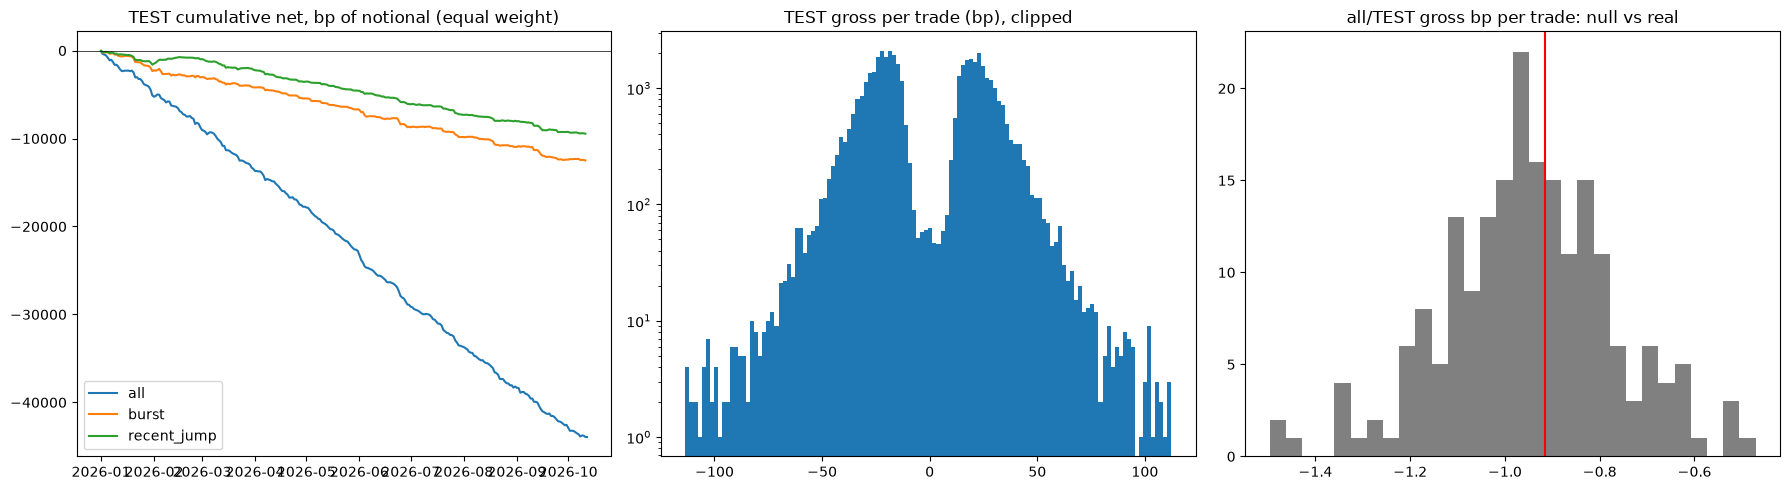

In [7]:
fig, ax = plt.subplots(1, 3, figsize=(18, 5))
for sp in jf.SPLITS:
    dn = jf.daily_net({a: jf.add_costs(t, jf.PRIMARY_VENUE) for a, t in TR[sp].items()}, 'test', list(TR[sp]))
    ax[0].plot(dn.index, 1e4 * dn.cumsum(), label=sp)
ax[0].axhline(0, c='k', lw=.5); ax[0].legend(); ax[0].set_title('TEST cumulative net, bp of notional (equal weight)')
z = pd.concat(TR['all'].values()); z = z[z.decision >= jf.DEV_END]
ax[1].hist(1e4 * z.gross.clip(-300, 100), bins=120); ax[1].set_yscale('log'); ax[1].set_title('TEST gross per trade (bp), clipped')
ax[2].hist(NULL['all_test'], bins=30, color='grey'); ax[2].axvline(REAL['all_test'], c='r'); ax[2].set_title('all/TEST gross bp per trade: null vs real')
plt.tight_layout(); plt.savefig(OUT / '01_plots.png', dpi=110); plt.show()